# 01 — Разведочный анализ: Telco Customer Churn

**Проект:** Разработка и автоматизация пайплайна машинного обучения для бинарной классификации
**Датасет:** [Telco Customer Churn (Kaggle)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) — 7 043 клиента телеком-компании, 20 признаков, целевая переменная `Churn` (уйдёт ли клиент).

**Задачи ноутбука (роль Data Scientist):**
1. знакомство с данными, типы признаков, статистики;
2. анализ пропусков и «битых» значений;
3. анализ выбросов;
4. распределения признаков и связь с целевой переменной;
5. корреляционный анализ;
6. первые гипотезы и наблюдения для feature engineering.

In [1]:
# --- Setup ---------------------------------------------------------------
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import DATASETS
from src.datasets import load_raw_by_key
from src.plotting import setup_style, save_figure

setup_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")

spec = DATASETS["telco"]
print(f"Источник (Kaggle): {spec.kaggle_url}")
print(f"Задача: {spec.task_summary}")

Источник (Kaggle): https://www.kaggle.com/datasets/blastchar/telco-customer-churn
Задача: Прогноз оттока клиентов телеком-компании: уйдёт ли клиент в ближайшее время (Churn = Yes/No).


## 1. Знакомство с данными

In [2]:
raw = load_raw_by_key("telco")
print(f"Размер таблицы: {raw.shape[0]} строк × {raw.shape[1]} признаков")
raw.head()

Размер таблицы: 7043 строк × 21 признаков


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.950,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.300,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.65,Yes


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.000,NaN,NaN,NaN,0.162,0.369,0.000,0.000,0.000,0.000,1.000
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.000,NaN,NaN,NaN,32.371,24.559,0.000,9.000,29.000,55.000,72.000
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Наблюдения:**
- `customerID` — уникальный идентификатор, для модели бесполезен (удалим);
- `SeniorCitizen` уже закодирован 0/1, остальные категориальные — строковые `Yes/No/...`;
- `tenure` — срок жизни клиента (месяцы), `MonthlyCharges` / `TotalCharges` — деньги;
- **`TotalCharges` имеет строковый тип** — признак того, что в колонке есть пустые значения.

## 2. Пропуски и «битые» значения

In [5]:
# Формальных NaN в датасете нет...
missing = raw.isna().sum()
print("NaN по колонкам:")
print(missing[missing > 0] if (missing > 0).any() else "  — нет —")

# ...но TotalCharges хранится как строка: ищем пустые/пробельные значения
tc = raw["TotalCharges"].astype(str).str.strip()
blank_mask = tc.eq("")
print(f"\nПустых значений TotalCharges: {blank_mask.sum()}")

blank_rows = raw.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]
blank_rows

NaN по колонкам:
  — нет —

Пустых значений TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.550,,No
753,3115-CZMZD,0,20.250,,No
936,5709-LVOEQ,0,80.850,,No
1082,4367-NUYAO,0,25.750,,No
1340,1371-DWPAZ,0,56.050,,No
3331,7644-OMVMY,0,19.850,,No
3826,3213-VVOLG,0,25.350,,No
4380,2520-SGTTA,0,20.000,,No
5218,2923-ARZLG,0,19.700,,No
6670,4075-WKNIU,0,73.350,,No


In [6]:
# Интересно: кто эти клиенты?
print("tenure у клиентов с пустым TotalCharges:", raw.loc[blank_mask, "tenure"].unique())
print("Churn у этих клиентов:", raw.loc[blank_mask, "Churn"].value_counts().to_dict())

tenure у клиентов с пустым TotalCharges: [0]
Churn у этих клиентов: {'No': 11}


**Вывод по пропускам:** все 11 «пустых» `TotalCharges` — это новые клиенты с `tenure = 0`
(они ещё не успели накопить счетов). Это **не случайные** пропуски.

Стратегия обработки (реализована в `src/`):
1. `TotalCharges` → числовой тип, пустые строки → `NaN`;
2. имплементация в sklearn-пайплайне: `SimpleImputer(strategy="median")` —
   медиана считается **только на train-выборке**, что исключает утечку;
3. дополнительно заводим признаки `avg_monthly_charge` и флаг новых клиентов,
   чтобы сохранить сигнал «новичок = риск». 

## 3. Баланс целевой переменной

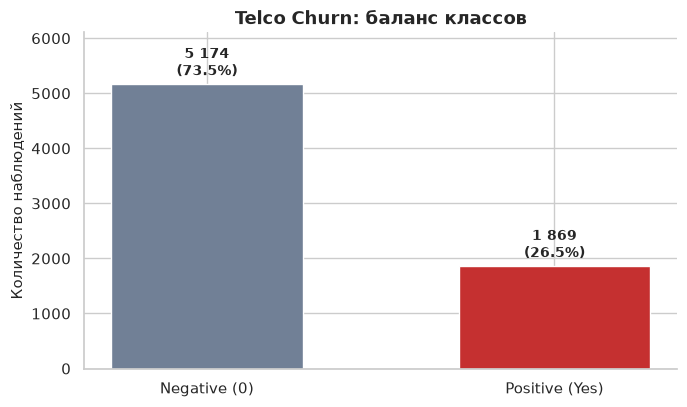

In [7]:
from src.plotting import plot_target_balance

y = (raw["Churn"] == "Yes").astype(int)
fig = plot_target_balance(y, "Telco Churn: баланс классов", positive_label="Yes")
plt.show()

**Наблюдение:** классы несбалансированы — 73.5% клиентов остаются, 26.5% уходят.
Поэтому Accuracy один вводит в заблуждение: «предсказывай всегда No» — и получи 73.5% accuracy.
Основные метрики для сравнения моделей — **F1 и ROC-AUC** (Precision/Recall тоже смотрим).

## 4. Числовые признаки vs Churn

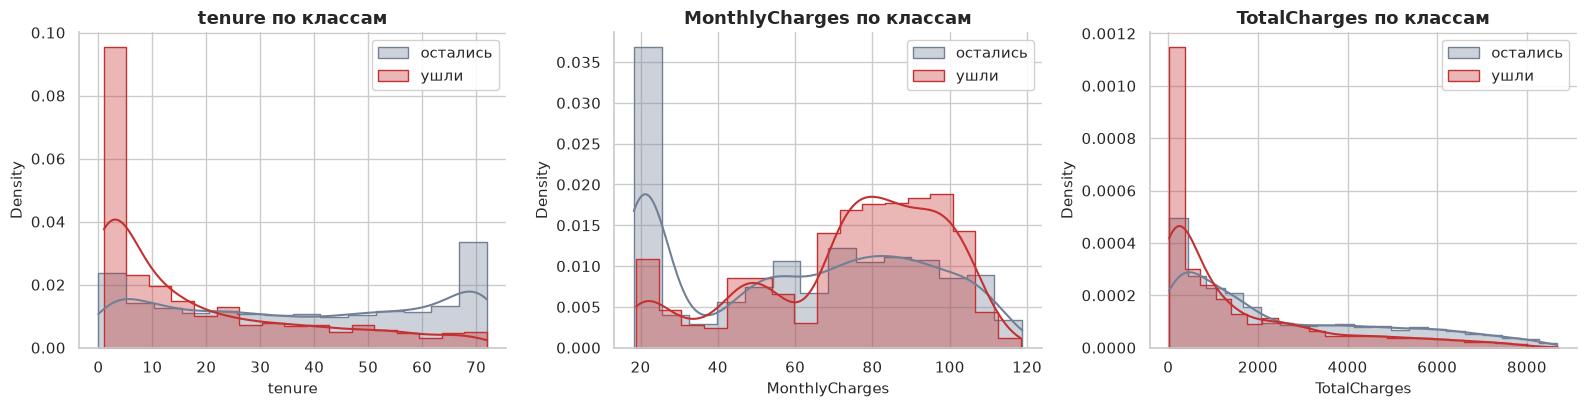

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

plot_df = raw.copy()
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    plot_df[col] = pd.to_numeric(plot_df[col].astype(str).str.strip(), errors="coerce")

for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    for cls, color, label in [(0, "#718096", "остались"), (1, "#c53030", "ушли")]:
        subset = plot_df.loc[y.eq(cls), col].dropna()
        sns.histplot(subset, kde=True, stat="density", element="step",
                     color=color, label=label, ax=ax, alpha=0.35)
    ax.set_title(f"{col} по классам")
    ax.legend()
fig.tight_layout()
plt.show()

**Наблюдения:**
- **`tenure`** — главный визуальный сигнал: у клиентов, которые уходят, распределение
  скошено к 0–10 месяцам. Долгожители почти не уходят;
- **`MonthlyCharges`** — ушедшие платили в среднем больше (дорогие тарифы + Fiber optic);
- `TotalCharges` — смесь двух эффектов (tenure × charges), учитываем это в FE.

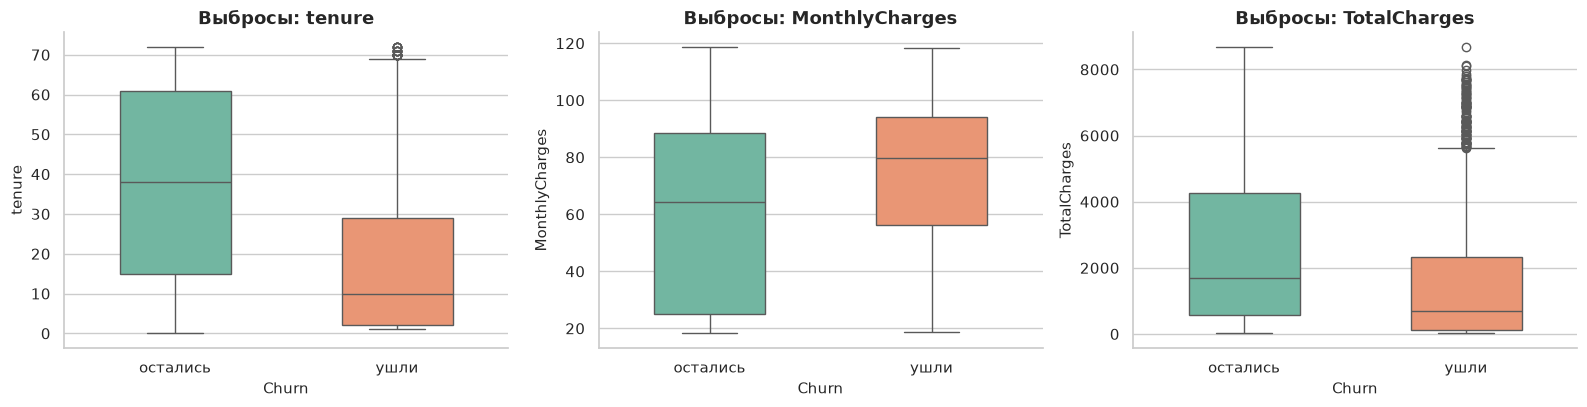

tenure: выбросов по правилу 1.5*IQR — 0 (0.0%)
MonthlyCharges: выбросов по правилу 1.5*IQR — 0 (0.0%)
TotalCharges: выбросов по правилу 1.5*IQR — 0 (0.0%)


In [9]:
# Выбросы: boxplots по классам
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
plot_df["Churn"] = plot_df["Churn"].map({"No": "остались", "Yes": "ушли"})
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(data=plot_df, x="Churn", y=col, hue="Churn", palette="Set2",
                ax=ax, legend=False, width=0.5)
    ax.set_title(f"Выбросы: {col}")
fig.tight_layout()
plt.show()

# Формальная проверка IQR
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    s = plot_df[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    out = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    print(f"{col}: выбросов по правилу 1.5*IQR — {out} ({out/len(s):.1%})")

**Вывод по выбросам:** явных «ошибочных» экстремумов нет (это реальные клиентские данные):
`tenure` равномерно заполняет 0–72 месяца, платежи находятся в разумном диапазоне.
Удалять выбросы не будем — они несут сигнал (например, максимальные `MonthlyCharges`).

## 5. Корреляционный анализ

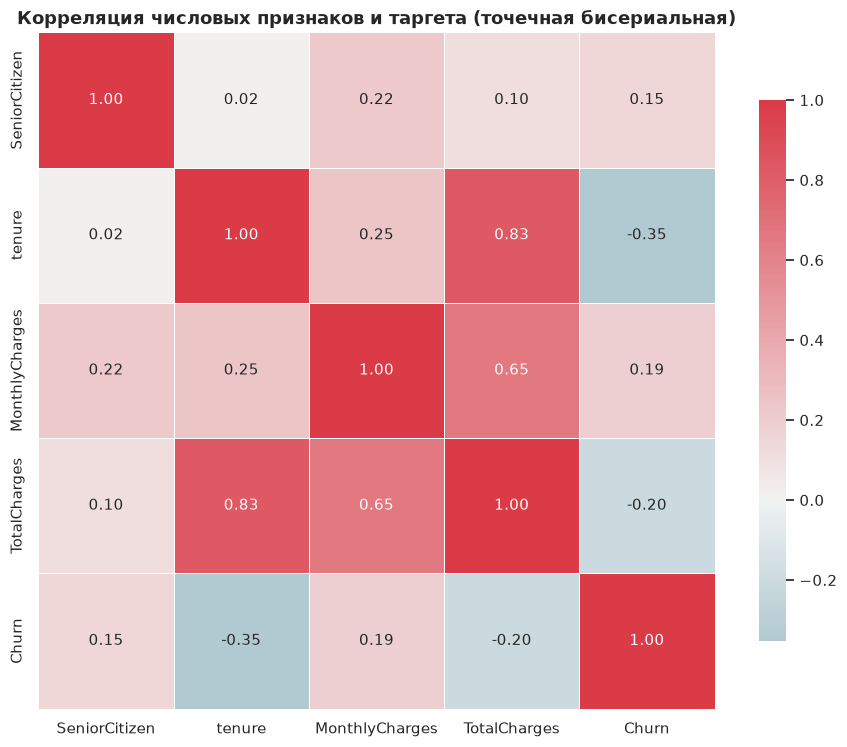

In [10]:
from src.plotting import plot_correlation_heatmap

numeric_cols = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
corr_df = plot_df.copy()
corr_df["Churn_bin"] = (corr_df["Churn"] == "ушли").astype(int)

fig = plot_correlation_heatmap(corr_df[numeric_cols + ["Churn_bin"]].rename(columns={"Churn_bin": "Churn"}),
                               "Корреляция числовых признаков и таргета (точечная бисериальная)", annot=True)
plt.show()

**Наблюдения:**
- `tenure` ↔ `TotalCharges` — ожидаемая мультиколлинеарность (TotalCharges ≈ tenure × средний платёж);
- `MonthlyCharges` ↔ `TotalCharges` — умеренная связь;
- с таргетом сильнее всех отрицательно коррелирует `tenure` (чем дольше клиент — тем стабильнее).

## 6. Категориальные признаки vs уровень оттока

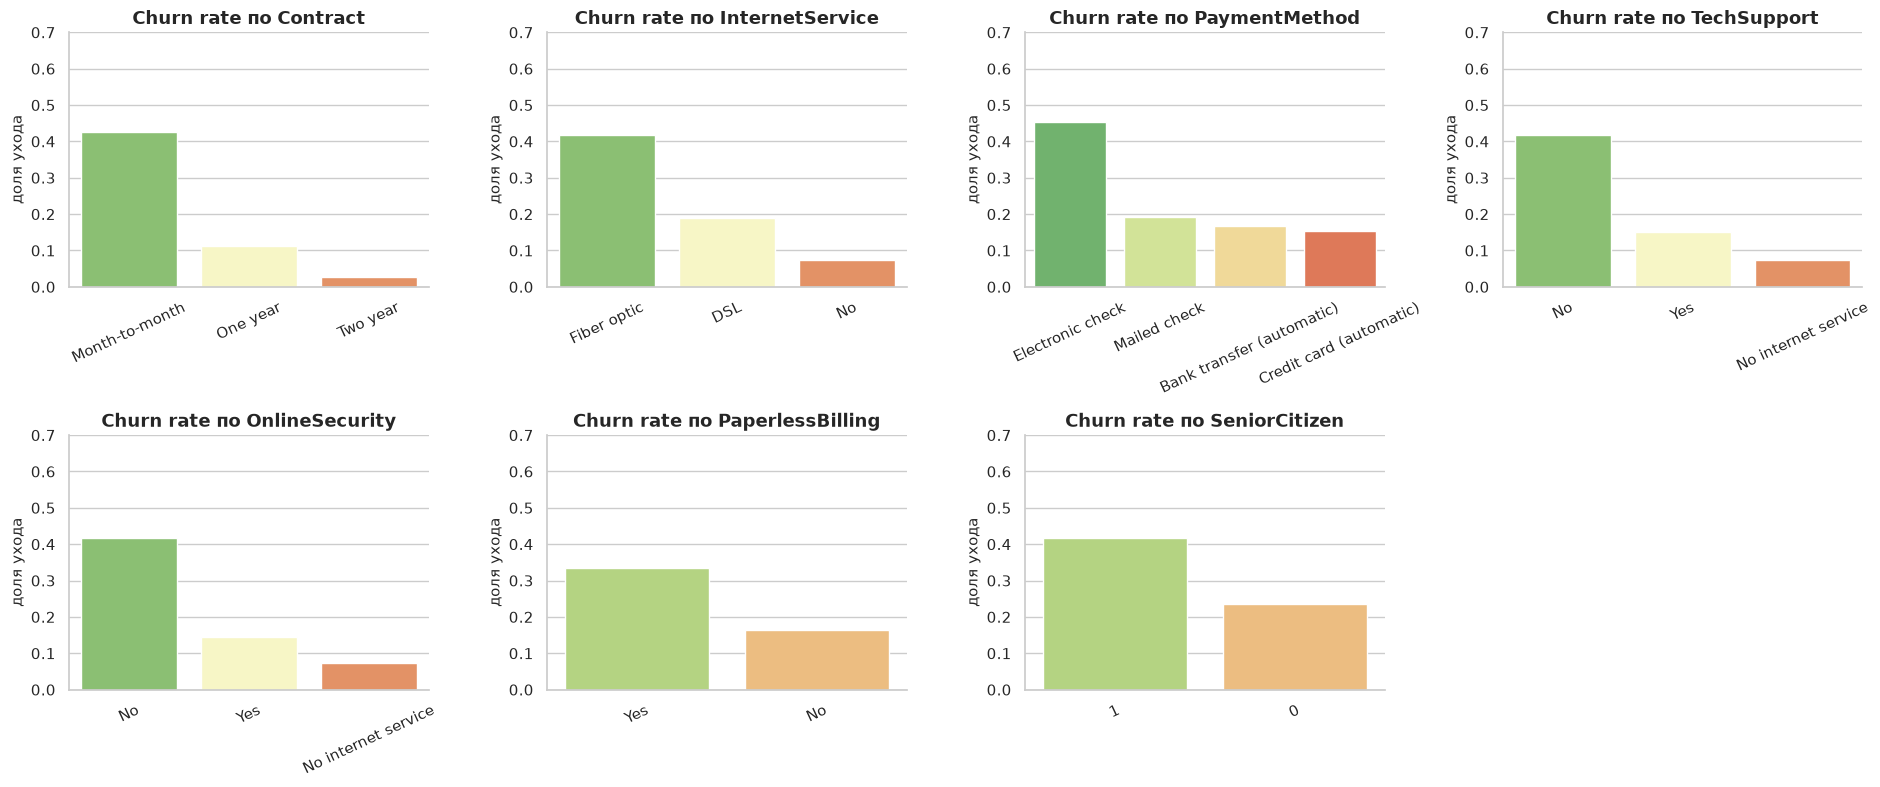

In [11]:
cat_cols = ["Contract", "InternetService", "PaymentMethod", "TechSupport",
            "OnlineSecurity", "PaperlessBilling", "SeniorCitizen"]

rates = []
for col in cat_cols:
    tab = raw.assign(churn=y).groupby(col, observed=True)["churn"].agg(["mean", "count"])
    tab.columns = ["churn_rate", "n"]
    tab["feature"] = col
    tab["level"] = tab.index.astype(str)
    rates.append(tab.reset_index(drop=True))
rates = pd.concat(rates, ignore_index=True)

fig, axes = plt.subplots(2, 4, figsize=(19, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    part = rates[rates["feature"] == col].sort_values("churn_rate", ascending=False)
    sns.barplot(data=part, x="level", y="churn_rate", hue="level",
                palette="RdYlGn_r", ax=ax, legend=False)
    ax.set_title(f"Churn rate по {col}")
    ax.set_xlabel("")
    ax.set_ylabel("доля ухода")
    ax.tick_params(axis="x", rotation=25)
    ax.set_ylim(0, 0.7)
axes.ravel()[-1].axis("off")
fig.tight_layout()
plt.show()

**Ключевые находки:**
- **`Contract`** — сильнейший категориальный предиктор: уход Month-to-month ≈ 43%,
  у Two year — ≈ 3%;
- **`InternetService = Fiber optic`** — аномально высокий отток (≈ 42%);
- **`PaymentMethod = Electronic check`** — отток ≈ 45% (в 2 раза выше остальных);
- `TechSupport`/`OnlineSecurity = No` — заметно повышают риск ухода;
- `SeniorCitizen` уходят чаще (≈ 42% против 24%).

## 7. Разведка признаков для feature engineering

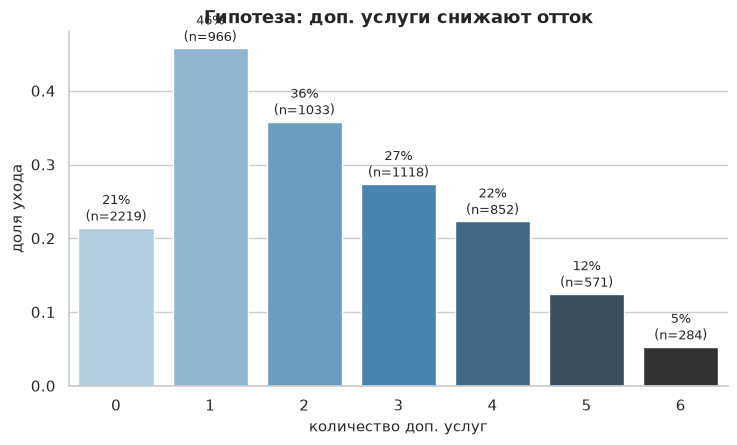

In [12]:
# Гипотеза: количество подключённых доп. услуг удерживает клиента
addon_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
              "TechSupport", "StreamingTV", "StreamingMovies"]
tmp = raw.copy()
tmp["num_addons"] = sum((tmp[c] == "Yes").astype(int) for c in addon_cols)
tmp["churn"] = y

fig, ax = plt.subplots(figsize=(8.5, 4.6))
addon_rate = tmp.groupby("num_addons")["churn"].agg(["mean", "count"])
sns.barplot(x=addon_rate.index, y=addon_rate["mean"], hue=addon_rate.index,
            palette="Blues_d", legend=False, ax=ax)
for i, (rate, n) in enumerate(zip(addon_rate["mean"], addon_rate["count"])):
    ax.text(i, rate + 0.01, f"{rate:.0%}\n(n={n})", ha="center", fontsize=9)
ax.set_xlabel("количество доп. услуг")
ax.set_ylabel("доля ухода")
ax.set_title("Гипотеза: доп. услуги снижают отток")
plt.show()

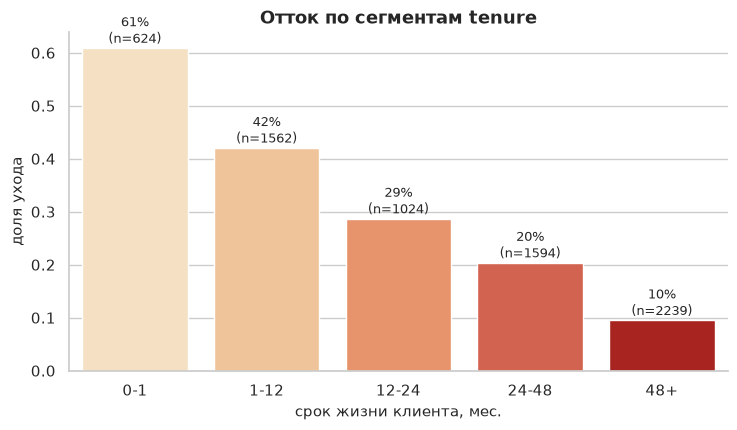

In [13]:
# Гипотеза: сегменты по tenure
tmp["tenure_group"] = pd.cut(tmp["tenure"], bins=[-0.01, 1, 12, 24, 48, np.inf],
                             labels=["0-1", "1-12", "12-24", "24-48", "48+"])
seg = tmp.groupby("tenure_group", observed=True)["churn"].agg(["mean", "count"])
fig, ax = plt.subplots(figsize=(8.5, 4.4))
sns.barplot(x=seg.index.astype(str), y=seg["mean"], hue=seg.index.astype(str),
            palette="OrRd", legend=False, ax=ax)
for i, (rate, n) in enumerate(zip(seg["mean"], seg["count"])):
    ax.text(i, rate + 0.01, f"{rate:.0%}\n(n={n})", ha="center", fontsize=9)
ax.set_xlabel("срок жизни клиента, мес.")
ax.set_ylabel("доля ухода")
ax.set_title("Отток по сегментам tenure")
plt.show()

## 8. Выводы по EDA (Telco)

| # | Находка | Решение в пайплайне |
|---|---------|---------------------|
| 1 | `TotalCharges` строковый, 11 пустых у клиентов с `tenure=0` | числовой тип + `SimpleImputer(median)` в sklearn-пайплайне |
| 2 | Дисбаланс классов 73/27 | метрики F1/ROC-AUC, `class_weight='balanced'`, stratified split |
| 3 | `tenure` — сильнейший числовой предиктор | + `tenure_group`, `is_new_customer` |
| 4 | Доп. услуги удерживают клиента (U-образная связь) | + `num_addons` |
| 5 | `Contract`, `PaymentMethod`, `InternetService` — сильные категории | one-hot кодирование в ColumnTransformer |
| 6 | Мультиколлинеарность tenure/TotalCharges | масштабирование + регуляризация; деревья нечувствительны |
| 7 | Выбросов-ошибок нет | данные не фильтруем, работаем как есть |

Переходим к ноутбуку **02** (второй датасет) и **03** (моделирование).